In [2]:
# read in packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

In [3]:
# read in data
mbta_df = gpd.read_file("mbtabus/MBTABUSSTOPS_PT.shp") # geometry data
rta_df = gpd.read_file("RTA_Stops/RTA_Stops.shp")
tracts_df = gpd.read_file("CENSUS2020/CENSUS2020TRACTS_POLY.shp")
pop_df = pd.read_csv("ACS_Population_Data/ACSDP5Y2024.DP05-Data.csv") # census tract
#vehicle_df = pd.read_csv("MVC_Snapshot_Black_Group.csv") block group
income_df = pd.read_csv("ACS_Income_data/ACSST5Y2024.S1902-Data.csv")

# find size of each dataset
print(mbta_df.shape)
print(pop_df.shape)
print(tracts_df.shape)
print(income_df.shape) # want just total med income and tract variable

(7810, 5)
(1621, 435)
(1613, 19)
(358, 171)


In [4]:
# # select columns
# mbta_df = mbta_df.loc[:, ["STOP_NAME", "geometry"]]
# rta_df = rta_df.loc[:, ["stop_name", "Agency", "geometry"]]
# tracts_df = tracts_df.loc[:, ["TRACTCE20", "POP20", "GEOID20", "geometry"]]

# make rtas the same crs
rta_df = rta_df.to_crs(tracts_df.crs)

# rework and combine bus stop datasets
mbta_df = mbta_df.rename(columns={"STOP_NAME": "stop_name"})
mbta_df = mbta_df.assign(Agency="MBTA")

stops_df = pd.concat([mbta_df, rta_df])

# spatial join with tracts
joined = gpd.sjoin(stops_df, tracts_df, how="inner", predicate="within")
joined

,STOP_ID,stop_name,TOWN,TOWN_ID,geometry,Agency,OBJECTID,stop_id,stop_code,stop_desc,...,AWATER20,INTPTLAT20,INTPTLON20,AREA_SQFT,AREA_ACRES,HOUSING20,POP20,BLK20_CNT,SHAPE_AREA,SHAPE_LEN
0,3077.0,Gallivan Blvd @ opp Marsh St,BOSTON,35.0,POINT (237120.669 892643.408),MBTA,NaN,NaN,NaN,NaN,...,146231.0,+42.2826719,-071.0479602,13273853.82,304.73,2047,4332,58,1.233186e+06,5173.282610
1,841.0,Lagrange St @ Virgil Rd,BOSTON,35.0,POINT (227915.195 892644.017),MBTA,NaN,NaN,NaN,NaN,...,0.0,+42.2873319,-071.1570120,14558816.72,334.23,1995,4708,64,1.352564e+06,5415.835419
2,446.0,Norfolk St @ Nelson St,BOSTON,35.0,POINT (234385.661 892644.944),MBTA,NaN,NaN,NaN,NaN,...,0.0,+42.2827979,-071.0797972,5294157.79,121.54,1323,3737,34,4.918453e+05,3208.721007
3,847.0,Lagrange St opp Virgil St,BOSTON,35.0,POINT (227912.601 892650.156),MBTA,NaN,NaN,NaN,NaN,...,0.0,+42.2873319,-071.1570120,14558816.72,334.23,1995,4708,64,1.352564e+06,5415.835419
4,3079.0,Adams St @ Minot St,BOSTON,35.0,POINT (236644.812 892651.99),MBTA,NaN,NaN,NaN,NaN,...,172846.0,+42.2775008,-071.0636843,18982476.54,435.78,2725,5791,62,1.763537e+06,6961.752677
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10352,NaN,LOC,NaN,NaN,POINT (239096.44 901494.912),MASSPORT,3704783.0,2502563,NaN,NaN,...,2032636.0,+42.3615186,-071.0073933,80833165.47,1855.68,35,79,60,7.509677e+06,18555.462648
10353,NaN,Stop 1,NaN,NaN,POINT (239508.139 900831.967),MASSPORT,3704784.0,2555232,NaN,NaN,...,2032636.0,+42.3615186,-071.0073933,80833165.47,1855.68,35,79,60,7.509677e+06,18555.462648
10354,NaN,Stop 2,NaN,NaN,POINT (239325.583 900939.047),MASSPORT,3704785.0,2555233,NaN,NaN,...,2032636.0,+42.3615186,-071.0073933,80833165.47,1855.68,35,79,60,7.509677e+06,18555.462648
10355,NaN,Stop 3,NaN,NaN,POINT (239140.785 901047.387),MASSPORT,3704786.0,2555234,NaN,NaN,...,2032636.0,+42.3615186,-071.0073933,80833165.47,1855.68,35,79,60,7.509677e+06,18555.462648


Text(0.5, 1.0, 'MA Bus Stops')

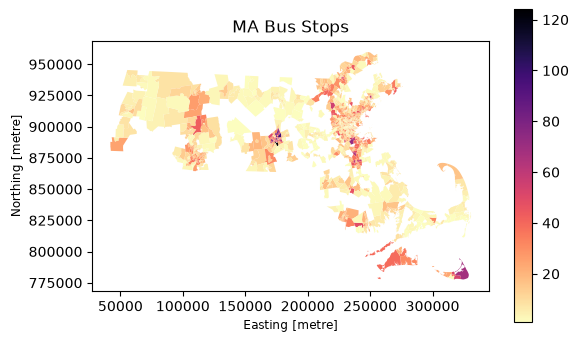

In [12]:
# get stops per tracts and merge with tracts
# counts = joined.groupby("GEOID20")["stop_name"].count()
# counts = counts.reset_index()
# counts = counts.rename(columns={"stop_name": "stop_count"})

# tracts_df = tracts_df.merge(counts, on="GEOID20", how="left")

tracts_df

# make visualizations
tracts_df.plot(column="stop_count_x", cmap="magma_r", legend=True)
plt.title("MA Bus Stops")

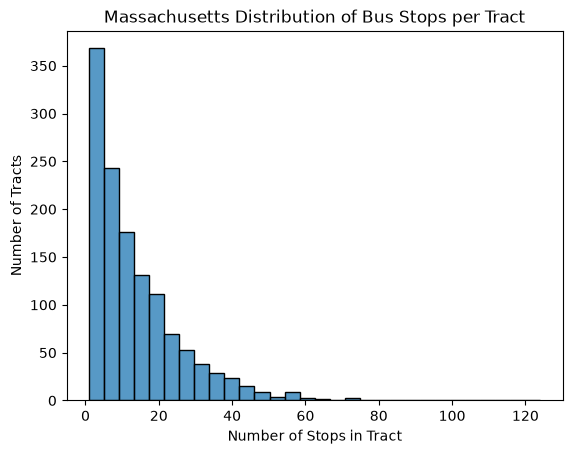

In [14]:
sns.histplot(data=tracts_df, x="stop_count", bins=30)
plt.xlabel("Number of Stops in Tract")
plt.ylabel("Number of Tracts")
plt.title("Massachusetts Distribution of Bus Stops per Tract")
plt.show()

In [23]:
# for each:
# select variables and explain significance
pop_df = pop_df.loc[:, ["GEO_ID", "NAME", "DP05_0001E"]]
#mbta_df = mbta_df.loc[:, ["STOP_NAME", "TOWN", "geometry"]]
#vehicle_df = vehicle_df.loc[:, ["BLOCKGROUP", "COUNT", "MUNICIPALITY"]]
income_df = income_df.loc[:, ["GEO_ID", "NAME", "S1902_C03_001E"]]

pop_df

,GEO_ID,NAME,DP05_0001E
0,Geography,Geographic Area Name,Estimate!!SEX AND AGE!!Total population
1,1400000US25001010100,Census Tract 101; Barnstable County; Massachus...,3703
2,1400000US25001010206,Census Tract 102.06; Barnstable County; Massac...,4404
3,1400000US25001010208,Census Tract 102.08; Barnstable County; Massac...,1708
4,1400000US25001010304,Census Tract 103.04; Barnstable County; Massac...,2649
...,...,...,...
1616,1400000US25027761100,Census Tract 7611; Worcester County; Massachus...,5009
1617,1400000US25027761200,Census Tract 7612; Worcester County; Massachus...,6632
1618,1400000US25027761300,Census Tract 7613; Worcester County; Massachus...,3594
1619,1400000US25027761401,Census Tract 7614.01; Worcester County; Massac...,4351


In [16]:
# summary of variables
# Estimate!!Mean income (dollars)!!HOUSEHOLD INCOME!!All households
# Estimate!!SEX AND AGE!!Total population
pop_df.describe(include='all') 
mbta_df.describe(include='all') 
tracts_df.describe(include='all') 
income_df.describe(include='all') 

# check for missing data, has none!!
pop_df.isna().sum()
mbta_df.isna().sum()
tracts_df.isna().sum()
income_df.isna().sum()


GEO_ID              0
NAME                0
S1902_C01_001E      0
S1902_C01_001M      0
S1902_C01_002E      0
                 ... 
S1902_C03_027E      0
S1902_C03_027M      0
S1902_C03_028E      0
S1902_C03_028M      0
Unnamed: 170      358
Length: 171, dtype: int64

In [ ]:
# create 2 viz for each intended dataset cambo

# 1: MBTA & Tracts viz?
#       - map of # of stops for each tract
#       - bar plot of # of stops for each tract idk sum of stops per tract
# 2: MBTA & Tracts & Income viz
#       - scatterplot of # of stops vs med income for each tract
#       - map w stops and income lol (low income?)
# 3: MBTA & Tracts & Population viz
#       - scatterplot of # of stops vs population for each tract
#       - map w stops and population?

In [21]:
# select columns
rta_df = rta_df.loc[:, ["stop_name", "Agency", "geometry"]]
tracts_df = tracts_df.loc[:, ["TRACTCE20", "POP20", "geometry"]]

# make rtas the same crs
rta_df = rta_df.to_crs(tracts_df.crs)

# rework and combine bus stop datasets
mbta_df = mbta_df.rename(columns={"STOP_NAME": "stop_name"})
mbta_df = mbta_df.assign(Agency="MBTA")

stops_df = pd.concat([mbta_df, rta_df])

stops_df.isna().sum()

stop_name    0
geometry     0
Agency       0
dtype: int64

In [17]:
# vehicles missing data
# vehicle_nas = vehicle_df[vehicle_df["BLOCKGROUP"].isna()]
# vehicle_nas.describe(include='all')

tracts_df = tracts_df.loc[:, ["TRACTCE20", "POP20", "GEOID20", "stop_count", "geometry"]]
tracts_df.to_file("combined_bus_loc.shp")

In [ ]:
# test ideas

# 1. CRS consistency: the MBTA, RTA and tract layers all use the same CRS before the spatial join.
# 2. No stops lost or double-counted: compare the number of joined rows with the number of stops. 
#    Any stop that matched no tract or two tracts should be explained, not silently dropped or counted twice.
# 3. Counts add up: the total of stop_count across all tracts equals the number of joined stops.
# 4. Valid count values: every stop_count is a whole number of 0 or more, and tracts with no stops show 0, not NaN.
# 5. Toy-data check of the counting logic: build a few hand-made squares and points where you know the answer, 
#    and confirm the counts come out exactly right.
# 6. One row per tract: GEOID20 is unique, and the number of tracts stays the same before and after each merge.
# 7. Income merge matches: most tracts actually get an income value after the merge. This catches the GEO_ID vs GEOID20 format mismatch.
# 8. Clean income values: income is numeric, the ACS description row and placeholders like "-" or "250,000+" are handled, and values fall in a plausible range.
# 9. Output file round-trip: reading combined_bus_loc.shp back gives the same rows, counts and geometry you wrote, and GEOID20 keeps its leading zeros.
# 10. Spot-check known tracts: a dense downtown Boston tract should have many stops and a rural tract few or none. 
#     This is a quick check that the results look reasonable.